# 10 · Rigid transforms SE(3), frame trees and camera projection

In [1]:
import mujoco, numpy as np, matplotlib.pyplot as plt
from vlacourse import TableTop

def T_from(R, p):
    T = np.eye(4); T[:3, :3] = R; T[:3, 3] = p
    return T

def T_inv(T):
    R, p = T[:3, :3], T[:3, 3]
    return T_from(R.T, -R.T @ p)

def quat2mat(q):
    m = np.zeros(9); mujoco.mju_quat2Mat(m, q)
    return m.reshape(3, 3)

def body_T_world(model, data, name):
    b = data.body(name)
    return T_from(b.xmat.reshape(3, 3), b.xpos)

def chain_T(model, data, name):
    """Compose parent->child transforms (body_pos, body_quat, joint rotations) from the world down."""
    bid = model.body(name).id
    chain = []
    while bid != 0:
        chain.append(bid)
        bid = model.body_parentid[bid]
    T = np.eye(4)
    for b in reversed(chain):
        T = T @ T_from(quat2mat(model.body_quat[b]), model.body_pos[b])
        for j in range(model.body_jntadr[b], model.body_jntadr[b] + model.body_jntnum[b]):
            if model.jnt_type[j] == mujoco.mjtJoint.mjJNT_HINGE:
                ax = model.jnt_axis[j]; ang = data.qpos[model.jnt_qposadr[j]]
                q = np.zeros(4); mujoco.mju_axisAngle2Quat(q, ax, ang)
                T = T @ T_from(quat2mat(q), np.zeros(3))
    return T

def camera_intrinsics(model, cam, w, h):
    fovy = np.deg2rad(model.cam_fovy[model.camera(cam).id])
    f = 0.5 * h / np.tan(fovy / 2)
    return np.array([[f, 0, w / 2], [0, f, h / 2], [0, 0, 1]])

def camera_T_world(data, cam):
    c = data.camera(cam)
    R_cam = c.xmat.reshape(3, 3) @ np.diag([1, -1, -1])
    return T_from(R_cam, c.xpos)

def project(points_w, K, T_wc):
    T_cw = T_inv(T_wc)
    pc = (T_cw[:3, :3] @ points_w.T).T + T_cw[:3, 3]
    uv = (K @ pc.T).T
    return uv[:, :2] / uv[:, 2:3], pc[:, 2]

In [2]:
env = TableTop(seed=4, cameras=("front",), image_size=(480, 640))
m, d = env.model, env.data
for name in ["link3", "link7", "hand"]:
    print(f"{name:6s} composed chain == MuJoCo xpos/xmat:", np.allclose(chain_T(m, d, name), body_T_world(m, d, name), atol=1e-9))

link3  composed chain == MuJoCo xpos/xmat: True
link7  composed chain == MuJoCo xpos/xmat: True
hand   composed chain == MuJoCo xpos/xmat: True


In [3]:
T_w_hand = body_T_world(m, d, "hand")
T_w_cube = body_T_world(m, d, f"cube_{env.cube_colors[0]}")
T_hand_cube = T_inv(T_w_hand) @ T_w_cube
print("cube position in the hand frame [m]:", T_hand_cube[:3, 3].round(3))
print("round trip T_w_hand @ T_hand_cube == T_w_cube:", np.allclose(T_w_hand @ T_hand_cube, T_w_cube))

cube position in the hand frame [m]: [-0.21   0.088  0.605]
round trip T_w_hand @ T_hand_cube == T_w_cube: True


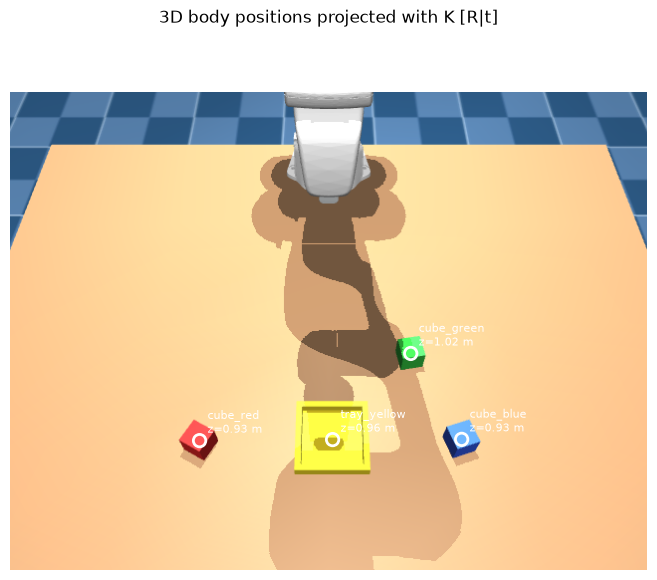

In [4]:
K = camera_intrinsics(m, "front", 640, 480)
T_wc = camera_T_world(d, "front")
names = [f"cube_{c}" for c in env.cube_colors] + [f"tray_{c}" for c in env.tray_colors] + ["hand"]
pts = np.array([d.body(n).xpos for n in names])
uv, depth = project(pts, K, T_wc)
img = env.render("front")
plt.figure(figsize=(9, 7)); plt.imshow(img)
for (u, v), n, z in zip(uv, names, depth):
    plt.scatter(u, v, s=80, facecolors="none", edgecolors="w", linewidths=2)
    plt.text(u + 8, v - 8, f"{n}\nz={z:.2f} m", color="w", fontsize=8)
plt.axis("off"); plt.title("3D body positions projected with K [R|t]"); plt.show()

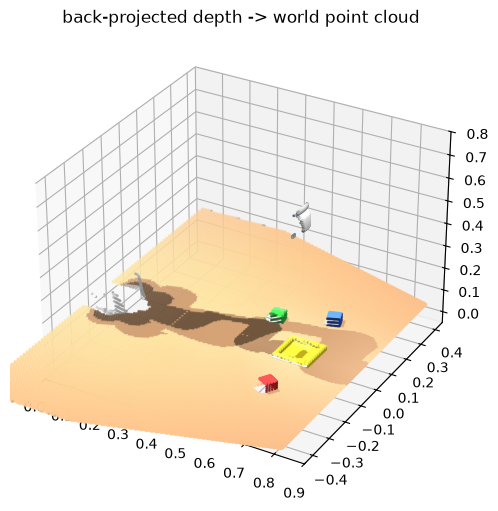

In [5]:
depth_img = env.render("front", depth=True)
v, u = np.mgrid[0:480, 0:640]
z = depth_img
x = (u - K[0, 2]) * z / K[0, 0]
y = (v - K[1, 2]) * z / K[1, 1]
pc_cam = np.stack([x, y, z], -1).reshape(-1, 3)[::7]
rgb = img.reshape(-1, 3)[::7] / 255.0
pc_w = (T_wc[:3, :3] @ pc_cam.T).T + T_wc[:3, 3]
keep = pc_w[:, 2] > -0.01
fig = plt.figure(figsize=(8, 6)); ax = fig.add_subplot(projection="3d")
ax.scatter(*pc_w[keep].T, c=rgb[keep], s=1)
ax.set_xlim(0, 0.9); ax.set_ylim(-0.45, 0.45); ax.set_zlim(-0.05, 0.8); ax.set_title("back-projected depth -> world point cloud"); plt.show()